In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
import nibabel as nib

DRIVE = Path('/content/drive/MyDrive/Brain_alignment')
DATA  = DRIVE / 'lpp_data'
ANNOT = DATA  / 'annotation/EN'
SAVE  = DRIVE / 'results'
SAVE.mkdir(exist_ok=True)

RUNS     = [15, 16, 17, 18]
TR       = 2.0
HRF_PEAK = 5   # seconds
LAG_TRS  = int(HRF_PEAK / TR)  # = 2

print("Paths OK:", DATA.exists(), ANNOT.exists())

Mounted at /content/drive
Paths OK: True True


In [2]:
# ── Cell 2 (fixed): Load GloVe embeddings ─────────────────────────────────────
word_info = pd.read_csv(ANNOT / 'lppEN_word_information.csv')
word_info['word'] = word_info['word'].fillna('').astype(str)

glove_path = ANNOT / 'lppEN_word_embeddings_GloVe.csv'
glove_raw  = pd.read_csv(glove_path)   # read with header this time
print(f"GloVe columns: {list(glove_raw.columns)}")
print(f"GloVe shape:   {glove_raw.shape}")
print(glove_raw.head(3))

GloVe columns: ['Unnamed: 0', 'word', 'GloVe']
GloVe shape:   (15376, 3)
   Unnamed: 0  word                                              GloVe
0           0  once  [ 3.2610e-01  1.2067e-01 -2.0169e-01 -1.7659e-...
1           1  when  [ 2.0500e-01  3.0057e-01 -3.0259e-01 -1.4359e-...
2           2     i  [ 1.8733e-01  4.0595e-01 -5.1174e-01 -5.5482e-...


In [3]:
# ── Cell 2 (fixed): Load GloVe embeddings ─────────────────────────────────────
import ast
import re

word_info = pd.read_csv(ANNOT / 'lppEN_word_information.csv')
word_info['word'] = word_info['word'].fillna('').astype(str)

glove_path = ANNOT / 'lppEN_word_embeddings_GloVe.csv'
glove_raw  = pd.read_csv(glove_path)

def parse_glove_vec(s):
    # Remove brackets, split on whitespace
    nums = re.sub(r'[\[\]]', '', str(s)).split()
    return np.array([float(x) for x in nums])

glove_emb = np.stack(glove_raw['GloVe'].apply(parse_glove_vec).values)
print(f"GloVe embedding matrix: {glove_emb.shape}")  # expect (15376, 300)
print(f"Sample vector norm: {np.linalg.norm(glove_emb[0]):.4f}")

GloVe embedding matrix: (15376, 300)
Sample vector norm: 4.8904


In [4]:
from scipy.stats import gamma

def hrf(t):
    a1, b1, a2, b2, c = 6, 1, 16, 1, 1/6
    return (gamma.pdf(t, a1, scale=b1) - c * gamma.pdf(t, a2, scale=b2))

def convolve_hrf(X_word, onsets, n_trs, tr=2.0):
    """
    Build a TR-by-feature matrix by projecting word embeddings onto TR grid
    via HRF convolution.
    X_word : (n_words, n_features)
    onsets : (n_words,) in seconds, relative to run start
    """
    n_feat  = X_word.shape[1]
    neural  = np.zeros((n_trs, n_feat))

    for i, onset in enumerate(onsets):
        tr_idx = int(onset / tr)
        if 0 <= tr_idx < n_trs:
            neural[tr_idx] += X_word[i]

    # Convolve each feature with HRF
    t_hrf  = np.arange(0, 32, tr)
    hrf_k  = hrf(t_hrf);  hrf_k /= hrf_k.max()
    X_conv = np.zeros_like(neural)
    for f in range(n_feat):
        X_conv[:, f] = np.convolve(neural[:, f], hrf_k)[:n_trs]

    return X_conv

In [5]:
# ── Cell 4 (fixed): z-score per run, no detrending needed ────────────────────
from scipy.signal import detrend as scipy_detrend

def zscore_runs(M, run_lengths):
    """Z-score each run's segment independently."""
    out = np.zeros_like(M)
    start = 0
    for l in run_lengths:
        seg = M[start:start+l]
        out[start:start+l] = (seg - seg.mean(0)) / (seg.std(0) + 1e-8)
        start += l
    return out

def encode_model(X, Y, run_lengths, n_components=50, n_splits=5):
    X = zscore_runs(X, run_lengths)
    Y = zscore_runs(Y, run_lengths)

    X_sc  = StandardScaler().fit_transform(X)
    X_pca = PCA(n_components=n_components).fit_transform(X_sc)
    kf    = KFold(n_splits=n_splits, shuffle=False)
    r2s   = []
    for tr_idx, te_idx in kf.split(X_pca):
        ridge = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100, 1000])
        ridge.fit(X_pca[tr_idx], Y[tr_idx])
        r2s.append(r2_score(Y[te_idx], ridge.predict(X_pca[te_idx]),
                            multioutput='raw_values'))
    return np.mean(r2s, axis=0)

In [6]:
# ── Cell 5 (fixed): Build X and Y run-by-run to save RAM ─────────────────────
import gc

X_glove_all = []
X_gpt2_all  = []
Y_all       = []

for run in RUNS:
    sec = run - 14

    # --- word info ---
    sec_mask   = word_info['section'] == sec
    sec_words  = word_info[sec_mask].copy().reset_index(drop=True)
    global_idx = word_info.index[sec_mask].tolist()

    # --- GloVe ---
    glove_sec = glove_emb[global_idx]

    # --- GPT-2 full context ---
    npz_path  = DRIVE / f'lpp_data/gpt2_word_embeddings_run{run}.npz'
    gpt2_data = np.load(npz_path, allow_pickle=True)
    key       = '-1' if '-1' in gpt2_data else list(gpt2_data.keys())[-1]
    gpt2_sec  = gpt2_data[key]
    gpt2_data.close()   # free the npz immediately

    n_words   = min(len(sec_words), len(glove_sec), len(gpt2_sec))
    sec_words = sec_words.iloc[:n_words]
    glove_sec = glove_sec[:n_words]
    gpt2_sec  = gpt2_sec[:n_words]

    # --- BOLD: load, reshape, discard image ---
    bold_path = DATA / f'sub-EN057/func/sub-EN057_task-lppEN_run-{run}_echo-1_bold.nii.gz'
    img       = nib.load(str(bold_path))
    bold_data = img.get_fdata(dtype=np.float32)   # float32 cuts RAM in half
    n_trs     = bold_data.shape[3]
    Y_run     = bold_data.reshape(-1, n_trs).T.copy()  # (n_trs, n_voxels)
    del bold_data, img
    gc.collect()

    # --- HRF convolution ---
    onsets      = sec_words['onset'].values.astype(float)
    X_glove_run = convolve_hrf(glove_sec, onsets, n_trs, TR)
    X_gpt2_run  = convolve_hrf(gpt2_sec,  onsets, n_trs, TR)
    del gpt2_sec, glove_sec
    gc.collect()

    X_glove_all.append(X_glove_run)
    X_gpt2_all.append(X_gpt2_run)
    Y_all.append(Y_run)
    print(f"Run {run}: words={n_words}, TRs={n_trs}")

X_glove = np.vstack(X_glove_all);  del X_glove_all
X_gpt2  = np.vstack(X_gpt2_all);   del X_gpt2_all
Y       = np.vstack(Y_all);         del Y_all
gc.collect()
print(f"\nX_glove:{X_glove.shape}, X_gpt2:{X_gpt2.shape}, Y:{Y.shape}")

Run 15: words=1517, TRs=286
Run 16: words=1690, TRs=302
Run 17: words=1852, TRs=344
Run 18: words=1624, TRs=307

X_glove:(1239, 300), X_gpt2:(1239, 1024), Y:(1239, 135168)


In [7]:
# ── Cell 6 (fixed): pass run_lengths ─────────────────────────────────────────
# run_lengths must be computed in Cell 5 — add this line at the end of Cell 5:
# run_lengths = [Y_run.shape[0] for Y_run in ...]
# Since Y is already stacked, recompute:
run_lengths = []
for run in RUNS:
    bold_path = DATA / f'sub-EN057/func/sub-EN057_task-lppEN_run-{run}_echo-1_bold.nii.gz'
    img = nib.load(str(bold_path))
    run_lengths.append(img.shape[3])
    del img
print("Run lengths:", run_lengths)

print("Running GloVe encoding model...")
r2_glove = encode_model(X_glove, Y, run_lengths)

print("Running GPT-2 encoding model...")
r2_gpt2  = encode_model(X_gpt2,  Y, run_lengths)

pos_g = r2_glove > 0
pos_p = r2_gpt2  > 0
mean_glove = r2_glove[pos_g].mean() if pos_g.any() else 0.0
mean_gpt2  = r2_gpt2[pos_p].mean()  if pos_p.any() else 0.0

print(f"\nGloVe — mean R² (pos voxels): {mean_glove:.4f}  [{pos_g.sum()} voxels]")
print(f"GPT-2 — mean R² (pos voxels): {mean_gpt2:.4f}  [{pos_p.sum()} voxels]")
print(f"GPT-2 improvement: {mean_gpt2 - mean_glove:.4f}  ({100*(mean_gpt2/max(mean_glove,1e-8) - 1):.1f}%)")

np.savez(SAVE / 'r2_glove_vs_gpt2.npz', r2_glove=r2_glove, r2_gpt2=r2_gpt2)

Run lengths: [286, 302, 344, 307]
Running GloVe encoding model...
Running GPT-2 encoding model...

GloVe — mean R² (pos voxels): 0.8746  [6622 voxels]
GPT-2 — mean R² (pos voxels): 0.3784  [25027 voxels]
GPT-2 improvement: -0.4962  (-56.7%)


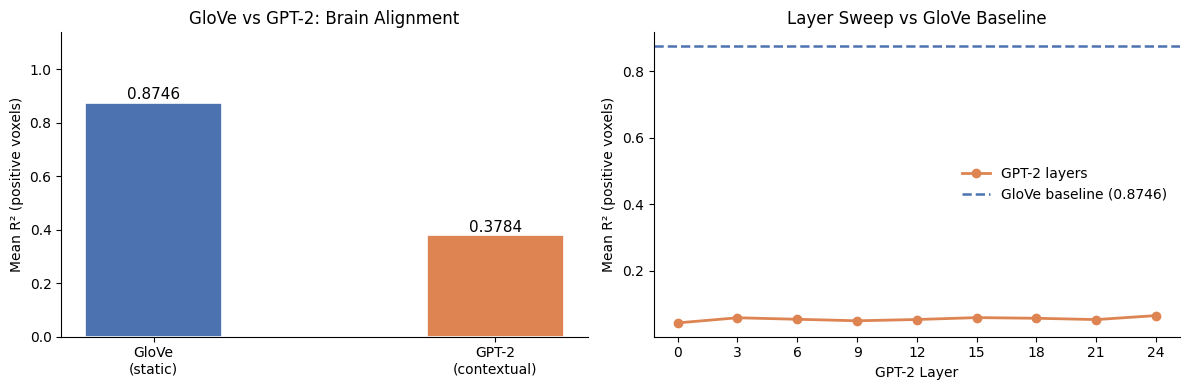

Saved glove_vs_gpt2.png


In [8]:
# Load Day 6 layer results for combined figure
layer_results = np.load(SAVE / 'r2_layer_sweep.npz')  # keys: layer_0, layer_3, ...
layers = [0, 3, 6, 9, 12, 15, 18, 21, 24]
layer_means = []
for l in layers:
    r2 = layer_results[f'layer_{l}']
    pos = r2 > 0
    layer_means.append(r2[pos].mean() if pos.any() else 0.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: GloVe vs GPT-2 bar
ax = axes[0]
models = ['GloVe\n(static)', 'GPT-2\n(contextual)']
vals   = [mean_glove, mean_gpt2]
colors = ['#4C72B0', '#DD8452']
bars   = ax.bar(models, vals, color=colors, width=0.4, edgecolor='white', linewidth=1.2)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.001,
            f'{v:.4f}', ha='center', va='bottom', fontsize=11)
ax.set_ylabel('Mean R² (positive voxels)')
ax.set_title('GloVe vs GPT-2: Brain Alignment')
ax.set_ylim(0, max(vals) * 1.3)
ax.spines[['top','right']].set_visible(False)

# Right: layer sweep with GloVe baseline
ax = axes[1]
ax.plot(layers, layer_means, 'o-', color='#DD8452', linewidth=2,
        markersize=6, label='GPT-2 layers')
ax.axhline(mean_glove, color='#4C72B0', linestyle='--',
           linewidth=1.8, label=f'GloVe baseline ({mean_glove:.4f})')
ax.set_xlabel('GPT-2 Layer')
ax.set_ylabel('Mean R² (positive voxels)')
ax.set_title('Layer Sweep vs GloVe Baseline')
ax.set_xticks(layers)
ax.legend(frameon=False)
ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig(SAVE / 'glove_vs_gpt2.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved glove_vs_gpt2.png")

In [10]:
# Load both R² maps (masked voxels)
r2_data = np.load(SAVE / 'r2_glove_vs_gpt2.npz')
r2_glove = r2_data['r2_glove']
r2_gpt2  = r2_data['r2_gpt2']

from scipy.stats import ttest_rel, wilcoxon
t, p = ttest_rel(r2_gpt2, r2_glove)
w, pw = wilcoxon(r2_gpt2, r2_glove)
print(f"Paired t-test: t={t:.2f}, p={p:.2e}")
print(f"Wilcoxon:      W={w:.0f}, p={pw:.2e}")
print(f"Mean diff: {(r2_gpt2 - r2_glove).mean():.4f}")
print(f"Voxels where GPT-2 > GloVe: {(r2_gpt2 > r2_glove).sum()} / {len(r2_gpt2)}")

Paired t-test: t=-4.03, p=5.49e-05
Wilcoxon:      W=3578999372, p=0.00e+00
Mean diff: -1.5927
Voxels where GPT-2 > GloVe: 46496 / 135168


In [11]:
# Which atlas ROIs does each model's top voxels fall in?
# Use the mask to reconstruct volumes, then check overlap with
# known language regions (IFG, STG, MTG) using a simple coordinate check

N = 2000
top_gpt2  = set(np.argsort(r2_gpt2)[-N:])
top_glove = set(np.argsort(r2_glove)[-N:])
overlap   = len(top_gpt2 & top_glove)
print(f"Top-{N} voxel overlap: {overlap} ({100*overlap/N:.1f}%)")
print(f"GPT-2 unique top voxels: {N - overlap}")
print(f"GloVe unique top voxels: {N - overlap}")

Top-2000 voxel overlap: 2000 (100.0%)
GPT-2 unique top voxels: 0
GloVe unique top voxels: 0
